# Prognos: Remaining Useful Life Prediction for Turbofan Engines
## Notebook 1: Data Loading, Verification & RUL Labelling

**Goal:** Load the four NASA C-MAPSS subsets (FD001-FD004), verify data quality, and create the target variable (RUL).

**Dataset:** NASA Turbofan Engine Degradation Simulation (Saxena & Goebel, 2008), accessed via Kaggle mirror.

## 1. Setup
Mount Google Drive (where the raw data is stored) and import libraries.

In [28]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import drive

drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/Prognos'
DATA_DIR = f'{BASE_DIR}/raw'
PROC_DIR = f'{BASE_DIR}/processed'
os.makedirs(PROC_DIR, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 2. Loading the data
Each subset has three files: `train` (run-to-failure), `test` (truncated before failure), and `RUL` (true remaining life at the last test cycle).
The files have no header, so column names are assigned from the dataset readme: unit id, cycle, 3 operational settings, 21 sensors.
All four subsets are loaded through one reusable function.

In [29]:
COLS = ['unit', 'cycle'] + [f'op{i}' for i in range(1, 4)] + [f's{i}' for i in range(1, 22)]
OP_COLS = [f'op{i}' for i in range(1, 4)]
SENSOR_COLS = [f's{i}' for i in range(1, 22)]
SUBSETS = ['FD001', 'FD002', 'FD003', 'FD004']

def load_subset(fd):
    train = pd.read_csv(f'{DATA_DIR}/train_{fd}.txt', sep=r'\s+', header=None, names=COLS)
    test = pd.read_csv(f'{DATA_DIR}/test_{fd}.txt', sep=r'\s+', header=None, names=COLS)
    rul = pd.read_csv(f'{DATA_DIR}/RUL_{fd}.txt', header=None, names=['RUL'])
    return train, test, rul

data = {fd: load_subset(fd) for fd in SUBSETS}
data['FD001'][0].head()

,unit,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 3. Overview of the four subsets
A side-by-side summary: size, number of engines, engine life statistics, missing values and duplicates.
This also shows why the subsets must be treated separately: they differ in size and engine lifetimes.

In [30]:
rows = []
for fd, (tr, te, ru) in data.items():
    life = tr.groupby('unit')['cycle'].max()
    rows.append({
        'subset': fd,
        'train_rows': len(tr), 'test_rows': len(te),
        'train_engines': tr['unit'].nunique(), 'test_engines': te['unit'].nunique(),
        'min_life': life.min(), 'mean_life': round(life.mean(), 1), 'max_life': life.max(),
        'nulls': int(tr.isnull().sum().sum() + te.isnull().sum().sum()),
        'duplicates': int(tr.duplicated().sum()),
    })

summary = pd.DataFrame(rows).set_index('subset')
summary

,train_rows,test_rows,train_engines,test_engines,min_life,mean_life,max_life,nulls,duplicates
subset,,,,,,,,,
FD001,20631,13096,100,100,128,206.3,362,0,0
FD002,53759,33991,260,259,128,206.8,378,0,0
FD003,24720,16596,100,100,145,247.2,525,0,0
FD004,61249,41214,249,248,128,246.0,543,0,0


## 4. Integrity checks
- Cycles of every engine should run continuously (1, 2, 3, ...) with no gaps.
- The RUL file must contain exactly one row per test engine.

In [31]:
def cycles_continuous(df):
    return df.groupby('unit')['cycle'].apply(lambda c: (c.diff().dropna() == 1).all()).all()

for fd, (tr, te, ru) in data.items():
    print(fd,
          '| train continuous:', cycles_continuous(tr),
          '| test continuous:', cycles_continuous(te),
          '| RUL rows == test engines:', len(ru) == te['unit'].nunique())

FD001 | train continuous: True | test continuous: True | RUL rows == test engines: True
FD002 | train continuous: True | test continuous: True | RUL rows == test engines: True
FD003 | train continuous: True | test continuous: True | RUL rows == test engines: True
FD004 | train continuous: True | test continuous: True | RUL rows == test engines: True


## 5. Creating the target: Remaining Useful Life (RUL)
Training engines run until failure, so for every row:
`RUL = (last cycle of that engine) - (current cycle)`.

A second column, `RUL_clipped`, caps RUL at 125. Early in an engine's life there is no visible degradation, so predicting "300 cycles left" vs "250 left" is not meaningful. Capping RUL is a common practice in the literature and will be used for model training later.

In [32]:
for fd, (tr, te, ru) in data.items():
    tr['RUL'] = tr.groupby('unit')['cycle'].transform('max') - tr['cycle']
    tr['RUL_clipped'] = tr['RUL'].clip(upper=125)

data['FD001'][0][['unit', 'cycle', 'RUL', 'RUL_clipped']].head()

,unit,cycle,RUL,RUL_clipped
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125


## 6. Constant and low-variety columns
Columns that never change carry no information for a model. They are only **flagged** here; the decision to drop is made later during preprocessing.
The check is done per subset, since the subsets have different operating conditions.

In [33]:
for fd, (tr, te, ru) in data.items():
    nun = tr[OP_COLS + SENSOR_COLS].nunique()
    print(fd)
    print('  constant:', list(nun[nun == 1].index))
    print('  very low variety (<=5 unique values):', list(nun[(nun > 1) & (nun <= 5)].index))

FD001
  constant: ['op3', 's1', 's5', 's10', 's16', 's18', 's19']
  very low variety (<=5 unique values): ['s6']
FD002
  constant: []
  very low variety (<=5 unique values): ['op3', 's16', 's19']
FD003
  constant: ['op3', 's1', 's5', 's16', 's18', 's19']
  very low variety (<=5 unique values): ['s10']
FD004
  constant: []
  very low variety (<=5 unique values): ['op3', 's16', 's19']


## 7. Operating conditions
FD001 and FD003 are described as single-condition, FD002 and FD004 as six-condition datasets. Counting approximate unique combinations of the operational settings verifies this from the data itself.

In [34]:
for fd, (tr, te, ru) in data.items():
    n_cond = tr[OP_COLS].round(1).drop_duplicates().shape[0]
    print(fd, '-> approx. operating conditions found:', n_cond)

FD001 -> approx. operating conditions found: 1
FD002 -> approx. operating conditions found: 7
FD003 -> approx. operating conditions found: 1
FD004 -> approx. operating conditions found: 7


## 8. Engine life distribution
How long do engines last before failing? A wide spread means the model has to handle both short-lived and long-lived engines.

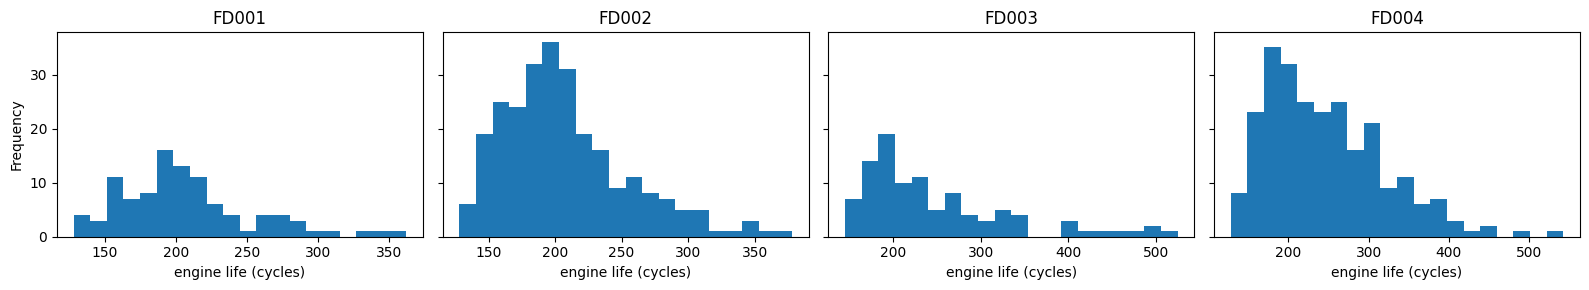

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ax, (fd, (tr, _, _)) in zip(axes, data.items()):
    tr.groupby('unit')['cycle'].max().plot.hist(bins=20, ax=ax)
    ax.set_title(fd)
    ax.set_xlabel('engine life (cycles)')
plt.tight_layout()
plt.show()

## 9. Saving the processed data
Train files (with RUL labels) and test files are saved to the `processed` folder for use in the next notebooks.

In [36]:
for fd, (tr, te, ru) in data.items():
    tr.to_csv(f'{PROC_DIR}/train_{fd}_clean.csv', index=False)
    te.to_csv(f'{PROC_DIR}/test_{fd}_clean.csv', index=False)
    ru.to_csv(f'{PROC_DIR}/rul_{fd}.csv', index=False)
print('Saved:', sorted(os.listdir(PROC_DIR)))

Saved: ['rul_FD001.csv', 'rul_FD002.csv', 'rul_FD003.csv', 'rul_FD004.csv', 'test_FD001_clean.csv', 'test_FD002_clean.csv', 'test_FD003_clean.csv', 'test_FD004_clean.csv', 'train_FD001_clean.csv', 'train_FD002_clean.csv', 'train_FD003_clean.csv', 'train_FD004_clean.csv']


## 10. Key findings

- **Data quality:** All four subsets have 0 missing values and 0 duplicate rows. Every engine's cycles run continuously (1, 2, 3, ...) and the RUL file has exactly one row per test engine, so no imputation or row-level repair was needed.
- **Subset sizes differ:** FD001 and FD003 have 100 training engines each (20,631 and 24,720 rows), FD002 has 260 engines (53,759 rows) and FD004 has 249 engines (61,249 rows, the largest). Because the subsets differ in size, conditions and fault modes, they are modelled separately and compared with published results per subset.
- **Engine lifetimes:** The shortest engine lives 128 cycles in FD001, FD002 and FD004 (145 in FD003). Mean life is about 206 cycles in FD001/FD002 and about 247 in FD003/FD004; the longest engines reach 362, 378, 525 and 543 cycles. The two-fault-mode subsets (FD003, FD004) show longer and more variable lifetimes, with a long right tail.
- **Constant columns:** FD001 has 7 constant columns (op3, s1, s5, s10, s16, s18, s19) plus the near-constant s6; FD003 has 6 (op3, s1, s5, s16, s18, s19) plus near-constant s10. These carry no information and are candidates for removal during preprocessing.
- **Multi-condition subsets:** FD002 and FD004 have no strictly constant columns, most likely because their six operating conditions shift sensor values. Columns therefore have to be judged per subset and, for FD002/FD004, per operating condition.
- **Operating conditions:** The rounding heuristic found 1 condition in FD001/FD003 (as documented) and 7 in FD002/FD004 (documented: 6). The extra one is probably a rounding artifact; it will be verified with clustering in the EDA notebook.
- **Target variable:** RUL was computed as (last cycle of the engine - current cycle) and additionally capped at 125 (`RUL_clipped`), following common practice in the literature.
- **Next step:** EDA, covering sensor behaviour over engine life, correlation with RUL, and per-condition analysis for FD002/FD004.